# 01 · Real A-share order book diagnostics

000400.SZ, 2022-06-01. Published messages reconstructed internally; no official reference snapshot. This notebook reads the actual primary artifacts, with no generated replacement data.

In [1]:
import json

import pandas as pd
from IPython.display import Image, display

from market_microstructure.utils.config import load_config
from market_microstructure.utils.paths import PROJECT_ROOT

ROOT = PROJECT_ROOT
config = load_config()
def table(name):
    return pd.read_csv(ROOT / 'outputs' / 'tables' / f'{name}.csv')
def figure(name):
    display(Image(filename=str(ROOT / 'outputs' / 'figures' / f'{name}.png')))
features = pd.read_parquet(ROOT / config['data']['features_path'])
assert set(features.asset) == {'000400.SZ'}
assert features.timestamp.dt.tz is not None


In [2]:
audit = json.loads((ROOT / 'outputs/tables/reconstruction_audit.json').read_text())
display(pd.Series(audit, name='replay audit'))
source = json.loads((ROOT / 'outputs/tables/public_sample_manifest.json').read_text())
display(pd.DataFrame(source['files'])[['file', 'bytes', 'sha256']])

raw_order_rows                                                                     365025
raw_trade_rows                                                                     324007
scope_rows_by_asset                     {'300274.SZ': 279784, '000400.SZ': 222651, '30...
selected_message_rows                                                              222651
outside_predeclared_asset_rows                                                     466381
asset                                                                           000400.SZ
date                                                                           2022.06.01
channel                                                                              2011
reception_clock_adjusted_rows                                                           0
reception_clock_max_adjustment_ms                                                     0.0
sequence_gaps                                                                      129983
gap_note  

,file,bytes,sha256
0,orders.csv,68778235,b6fc64db484641298cc35070e31bc9f77b8714dc7bcc0c...
1,trans.csv,60260120,bd8658b8d4092451771514f5afab8388fe4669ef044b90...


## Schema and data quality

Validation rejects nonfinite prices/sizes, duplicate keys and crossed books. The 41 rejected crossed reconstruction endpoints were counted upstream. Their exclusion is not evidence of official accuracy.

In [3]:
from market_microstructure.data.validation import validate_orderbook

book = pd.read_parquet(ROOT / config['data']['input_path'])
validated, audit_rows = validate_orderbook(book)
assert audit_rows.removed == 0
display(book[['timestamp','asset','bid_price_1','ask_price_1','bid_size_1','ask_size_1']].head())
display(features[['spread_bps','imbalance_1','imbalance_k','total_depth','microprice_deviation_bps']].describe())

,timestamp,asset,bid_price_1,ask_price_1,bid_size_1,ask_size_1
0,2022-06-01 01:30:00+00:00,000400.SZ,19.16,19.17,24241.0,500.0
1,2022-06-01 01:30:01+00:00,000400.SZ,19.19,19.25,23900.0,1500.0
2,2022-06-01 01:30:02+00:00,000400.SZ,19.19,19.28,2700.0,5700.0
3,2022-06-01 01:30:03+00:00,000400.SZ,19.17,19.28,15900.0,5700.0
4,2022-06-01 01:30:04+00:00,000400.SZ,19.20,19.22,16100.0,2000.0


,spread_bps,imbalance_1,imbalance_k,total_depth,microprice_deviation_bps
count,14179.000000,14179.000000,14179.000000,14179.000000,14179.000000
mean,7.976662,-0.019044,-0.111559,160246.085549,-0.231634
std,5.986730,0.657472,0.459045,92689.269529,3.365424
min,4.806537,-0.999137,-0.987338,14900.000000,-30.206746
25%,4.964011,-0.666667,-0.488298,92238.500000,-1.991461
50%,5.124263,-0.006035,-0.128725,138151.000000,-0.017482
75%,9.891197,0.603285,0.257231,205839.500000,1.777808
max,79.601990,0.999948,0.949682,693800.000000,22.999949


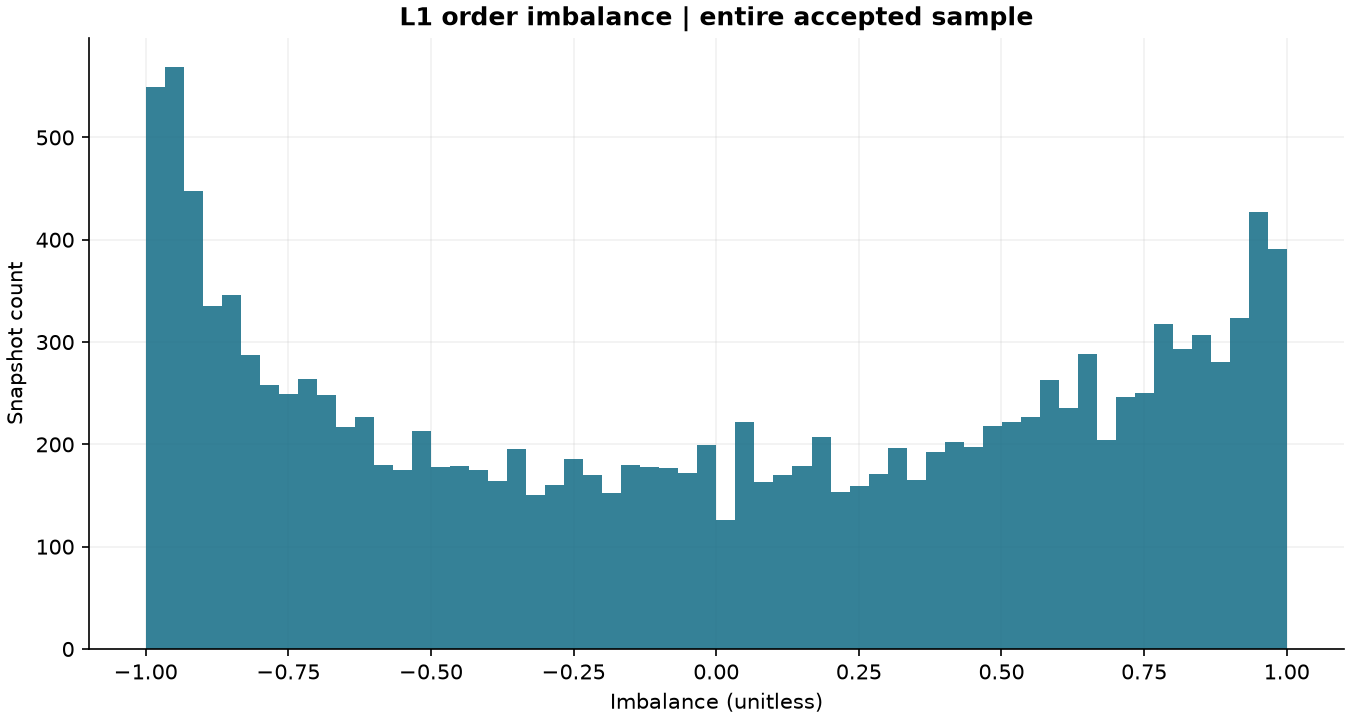

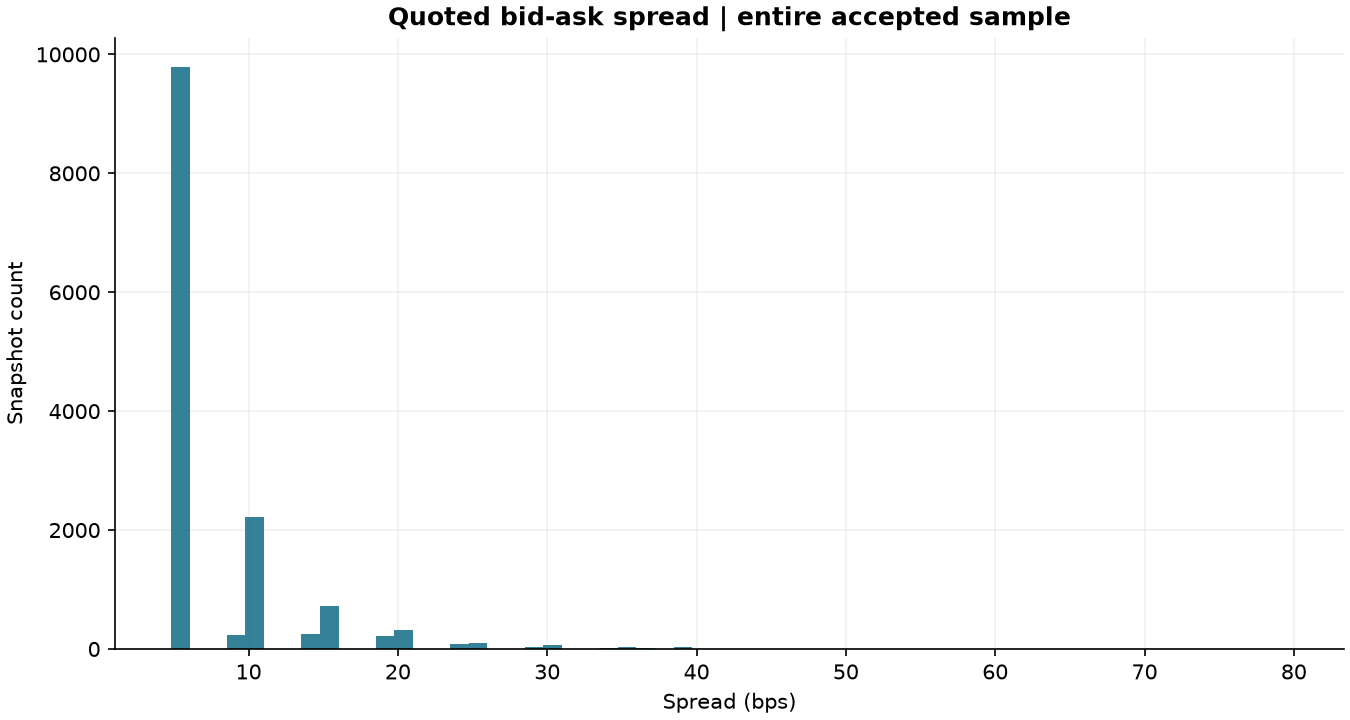

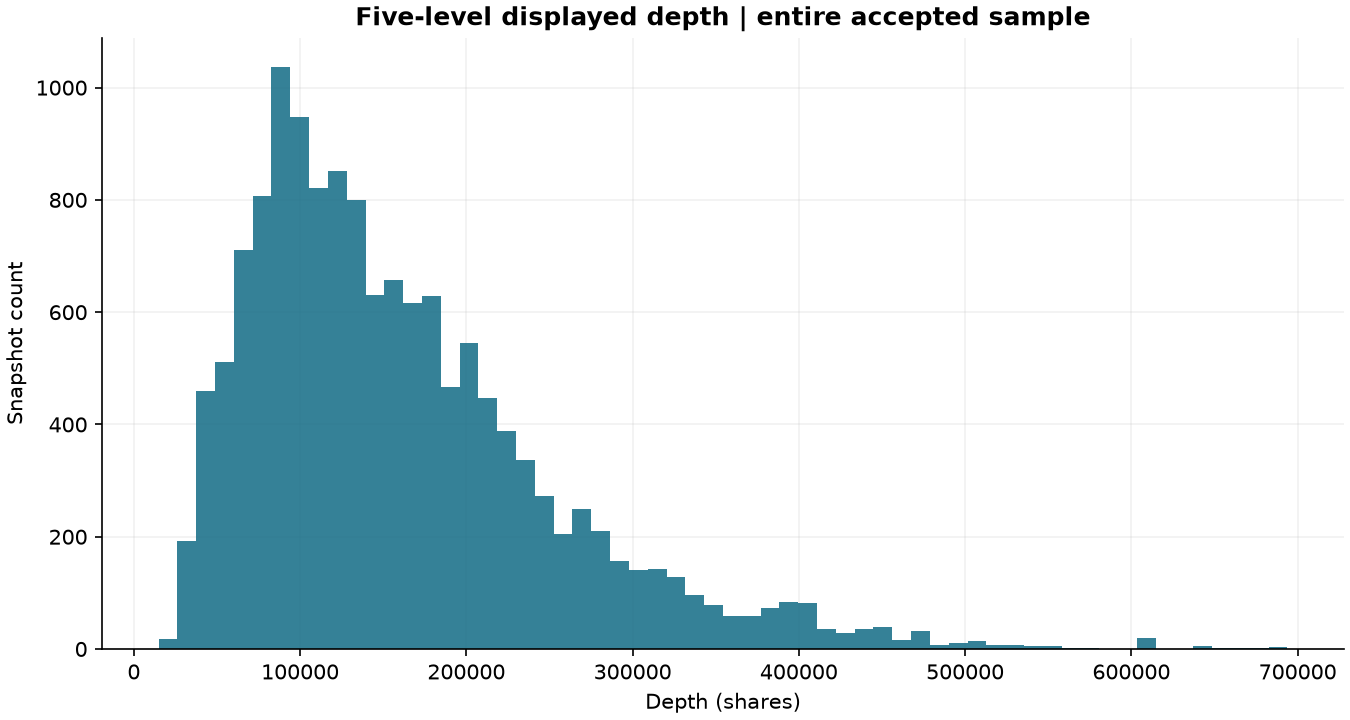

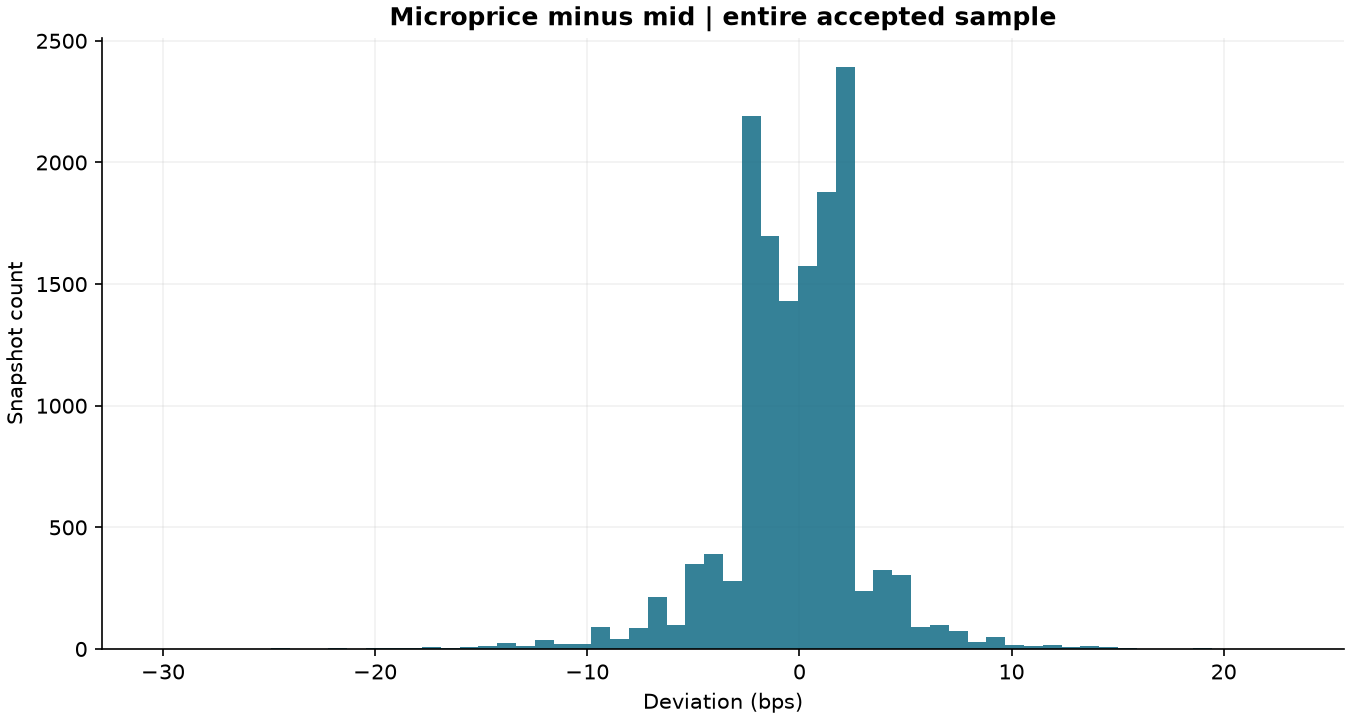

In [4]:
figure('order_imbalance_distribution')
figure('spread_distribution')
figure('depth_distribution')
figure('microprice_deviation_distribution')

## Causal feature check

Modify only future real quotes and compare the unchanged prefix. Labels are future outcomes and are excluded from model features.

In [5]:
from market_microstructure.features.feature_pipeline import build_features, feature_columns

cutoff = book.timestamp.iloc[1000]
changed = book.copy()
for column in book.columns:
    if column.startswith(('bid_price_', 'ask_price_')):
        changed.loc[book.timestamp > cutoff, column] *= 1.1
first = build_features(book, levels=5, weighting='distance_decay', rolling_window=50, min_periods=10)
second = build_features(changed, levels=5, weighting='distance_decay', rolling_window=50, min_periods=10)
mask = book.timestamp <= cutoff
pd.testing.assert_frame_equal(first.loc[mask, feature_columns(first)], second.loc[mask, feature_columns(second)])
print('Future quote mutation leaves all prefix predictors unchanged.')

Future quote mutation leaves all prefix predictors unchanged.


Trade intensity describes active snapshot intervals, not a precise message arrival rate. Sampling is one second and resets at lunch; finer exchange latency is not identified.